============================================================
v7-2 原版 + Stage 3 CVAS 句子層級 Pipeline

Stage 1 & 2：完全複製自 v7-2，不做任何改動
Stage 3：新增，直接接在 v7-2 後面

Stage 3 設計原則：
  句子 → 滑動窗口找出所有「修飾詞+情感詞」短語
  → 每個短語走 Stage1+2 遞迴鏈 → 短語 VA + c_mod
  → NNsent 用 c_mod 決定哪個短語對整句情感最重要
  → 加權聚合 → 整句 VA
============================================================


## 安裝


In [2]:
# !pip install transformers torch pandas numpy scikit-learn scipy matplotlib -q


## 匯入（v7-2 原版）


In [3]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from scipy.stats import kendalltau, spearmanr, pearsonr
from transformers import AutoTokenizer, AutoModel
from torch.utils.data import TensorDataset, DataLoader

from google.colab import drive
drive.mount('/content/drive')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'使用裝置: {device}')

try:
    import subprocess
    subprocess.run(['apt-get', 'install', '-y', 'fonts-noto-cjk'], capture_output=True)
    matplotlib.rc('font', family='Noto Sans CJK JP')
except:
    pass


Mounted at /content/drive
使用裝置: cuda


## 路徑設定（v7-2 原版）


In [4]:
BASE     = '/content/drive/MyDrive/研究/dimABSA/DataSets/ChineseEmoBank'
SAVE_DIR = '/content/drive/MyDrive/研究/dimABSA/models'
BERT_NAME = 'hfl/chinese-bert-wwm-ext'

import os; os.makedirs(SAVE_DIR, exist_ok=True)


## 資料載入（v7-2 原版）


In [5]:
def read_csv_robust(path, sep='\t'):
    for enc in ['utf-8', 'utf-8-sig', 'big5', 'gb18030', 'cp950']:
        try:
            df = pd.read_csv(path, sep=sep, encoding=enc)
            print(f'  -> {path.split("/")[-1]} 使用編碼: {enc}')
            return df
        except (UnicodeDecodeError, UnicodeError):
            continue
    return pd.read_csv(path, sep=sep, encoding='utf-8', encoding_errors='replace')

cvaw = read_csv_robust(f'{BASE}/CVAW_SD/CVAW_all_SD.csv')
cvap = read_csv_robust(f'{BASE}/CVAP_SD/CVAP_all_SD.csv')
cvas = read_csv_robust(f'{BASE}/CVAS_SD/CVAS_all.csv')
print(f'CVAW: {len(cvaw)}  CVAP: {len(cvap)}  CVAS: {len(cvas)}')


  -> CVAW_all_SD.csv 使用編碼: utf-8
  -> CVAP_all_SD.csv 使用編碼: utf-8
  -> CVAS_all.csv 使用編碼: utf-8
CVAW: 5512  CVAP: 2250  CVAS: 2583


## 正規化（v7-2 原版）


In [6]:
def normalize_va(df, val_col='Valence_Mean', aro_col='Arousal_Mean'):
    df = df.copy()
    df[val_col] = pd.to_numeric(df[val_col], errors='coerce')
    df[aro_col] = pd.to_numeric(df[aro_col], errors='coerce')
    before = len(df)
    df = df.dropna(subset=[val_col, aro_col]).reset_index(drop=True)
    if before - len(df) > 0:
        print(f'  ⚠ 清除 {before-len(df)} 筆髒資料')
    df['valence'] = (df[val_col] - 1) / 8.0
    df['arousal']  = (df[aro_col] - 1) / 8.0
    return df

cvaw = normalize_va(cvaw)
cvap = normalize_va(cvap)
cvas = normalize_va(cvas)


## 片語切割（v7-2 原版，完全不改）


In [7]:
cvaw_word_set = set(cvaw['Word'].astype(str).tolist())
max_core_len  = max(len(w) for w in cvaw_word_set)

NEGATION_CUES = {
    '不是很','並不太','並不是','不怎麼','不太','不是','並不',
    '沒有','沒','不','無','未','別','勿'
}
DEGREE_CUES = {
    '超級','極為','非常','相當','十分','更加','格外','特別',
    '有點','稍微','很','太','更','極','超'
}
COMPOSITE_MODIFIERS = {
    '不是很','並不太','並不是很','沒有很','不怎麼','不太'
}
MODIFIER_LEXICON = sorted(
    COMPOSITE_MODIFIERS | NEGATION_CUES | DEGREE_CUES,
    key=len, reverse=True
)

def normalize_text(s):
    s = str(s).strip()
    for ch in '，。！？、,.!?;；：「」『』（）() ':
        s = s.replace(ch, '')
    return s

def split_modifier_chain(modifier_text):
    txt = normalize_text(modifier_text)
    if not txt: return []
    mods, i = [], 0
    while i < len(txt):
        matched = next((tok for tok in MODIFIER_LEXICON if txt.startswith(tok, i)), txt[i:i+1])
        mods.append(matched); i += len(matched)
    merged, j = [], 0
    while j < len(mods):
        if j+1 < len(mods) and (mods[j]+mods[j+1]) in COMPOSITE_MODIFIERS:
            merged.append(mods[j]+mods[j+1]); j += 2
        else:
            merged.append(mods[j]); j += 1
    return merged

def split_phrase(phrase, cvaw_words):
    phrase = normalize_text(phrase)
    candidates = []
    for core_len in range(min(max_core_len, len(phrase)-1), 0, -1):
        core = phrase[-core_len:]; modifier = phrase[:-core_len]
        if core in cvaw_words and len(modifier) > 0:
            mod_tokens = split_modifier_chain(modifier)
            neg_hits = sum(t in NEGATION_CUES for t in mod_tokens)
            deg_hits = sum(t in DEGREE_CUES   for t in mod_tokens)
            candidates.append(((neg_hits+deg_hits, neg_hits, core_len), modifier, core, mod_tokens))
    if candidates:
        _, modifier, core, mod_tokens = max(candidates, key=lambda x: x[0])
        return modifier, core, mod_tokens
    return None, None, []

mods, cores, mod_chains = [], [], []
for phrase in cvap['Phrase']:
    m, c, chain = split_phrase(phrase, cvaw_word_set)
    mods.append(m); cores.append(c); mod_chains.append(chain)
cvap['modifier']       = mods
cvap['core_word']      = cores
cvap['modifier_chain'] = mod_chains
cvap_aligned = cvap.dropna(subset=['modifier','core_word']).copy()
print(f'CVAP 對齊: {len(cvap_aligned)}/{len(cvap)} 筆')

# 訓練/測試切分
cvaw_train, cvaw_test = train_test_split(cvaw,         test_size=0.2, random_state=42)
cvap_train, cvap_test = train_test_split(cvap_aligned, test_size=0.2, random_state=42)
cvas_train, cvas_test = train_test_split(cvas,         test_size=0.2, random_state=42)


CVAP 對齊: 2249/2250 筆


## BERT 載入（v7-2 原版）


In [8]:
print(f'載入 {BERT_NAME}...')
tokenizer  = AutoTokenizer.from_pretrained(BERT_NAME)
bert_model = AutoModel.from_pretrained(BERT_NAME).to(device)
bert_model.eval()
BERT_DIM = bert_model.config.hidden_size
print(f'✅ 載入完成 | hidden size: {BERT_DIM}')

@torch.no_grad()
def get_bert_vec(text):
    bert_model.eval()
    enc = tokenizer(str(text), return_tensors='pt',
                    padding=True, truncation=True, max_length=16).to(device)
    return bert_model(**enc).last_hidden_state[:,0,:].squeeze(0).cpu().numpy().astype(np.float32)

@torch.no_grad()
def get_bert_pair_vec(modifier, target_text):
    bert_model.eval()
    enc = tokenizer(str(modifier), str(target_text), return_tensors='pt',
                    padding=True, truncation=True, max_length=24).to(device)
    return bert_model(**enc).last_hidden_state[:,0,:].squeeze(0).cpu().numpy().astype(np.float32)

@torch.no_grad()
def get_bert_vecs_batch(texts, batch_size=64):
    bert_model.eval(); all_vecs = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i+batch_size], return_tensors='pt',
                        padding=True, truncation=True, max_length=16).to(device)
        all_vecs.append(bert_model(**enc).last_hidden_state[:,0,:].cpu().numpy())
    return np.concatenate(all_vecs).astype(np.float32)


載入 hfl/chinese-bert-wwm-ext...


config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/19.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/110k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/269k [00:00<?, ?B/s]

...

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  412MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: hfl/chinese-bert-wwm-ext
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ 載入完成 | hidden size: 768


## NNword & NNmod（v7-2 原版，完全不改）


In [9]:
class NNword(nn.Module):
    def __init__(self, bert_dim=768):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(bert_dim, 256), nn.BatchNorm1d(256), nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, 2)
        )
    def forward(self, bert_vec):
        out = torch.sigmoid(self.net(bert_vec))
        return out[:,0:1], out[:,1:2]

class NNmod(nn.Module):
    def __init__(self, bert_dim=768):
        super().__init__()
        feat_dim = bert_dim + 4
        self.fc1 = nn.Linear(feat_dim, 192); self.ln1 = nn.LayerNorm(192)
        self.fc2 = nn.Linear(192, 64);       self.ln2 = nn.LayerNorm(64)
        self.fc3 = nn.Linear(64, 2);         self.drop = nn.Dropout(0.1)
        for layer in [self.fc1, self.fc2, self.fc3]:
            nn.init.xavier_uniform_(layer.weight); nn.init.zeros_(layer.bias)

    def forward(self, int_val, int_aro, bert_mod_ctx):
        va_feat = torch.cat([int_val, int_aro, int_val*int_aro, int_val-int_aro], dim=1)
        x = torch.cat([bert_mod_ctx, va_feat], dim=1)
        h = torch.relu(self.ln1(self.fc1(x))); h = self.drop(h)
        h = torch.relu(self.ln2(self.fc2(h)))
        delta   = torch.tanh(self.fc3(h)) * 0.5
        out_v   = torch.sigmoid(torch.logit(int_val.clamp(0.01,0.99)) + delta[:,0:1]*3)
        out_a   = torch.sigmoid(torch.logit(int_aro.clamp(0.01,0.99)) + delta[:,1:2]*3)
        c_mod_v = delta[:,0:1] + 0.5
        c_mod_a = delta[:,1:2] + 0.5
        return out_v, out_a, c_mod_v, c_mod_a

print('NNword / NNmod（v7-2）定義完成')


NNword / NNmod（v7-2）定義完成


## NNsent（Stage 3 新增）


In [10]:
class NNsent(nn.Module):
    """
    Stage 3：CVAS 句子層級 Pipeline 聚合

    輸入（來自 Stage 1+2 的 Pipeline 結果）：
      span_vas   (B, MAX_SPANS, 2)  — 每個情感短語的最終 VA
      span_cmods (B, MAX_SPANS, 2)  — NNmod 的 c_mod（修飾詞強度）
      span_hits  (B, MAX_SPANS, 1)  — 1=有修飾詞走完整鏈, 0=只有核心詞
      span_mask  (B, MAX_SPANS)     — 有效 span 的 mask

    注意力邏輯：
      c_mod 離 0.5 越遠 → 修飾詞影響越大 → 這個 span 越重要
      hit=0 → 沒有修飾詞 → 模型學會給較低注意力
      → 自動找出對整句 VA 貢獻最大的情感短語
    """
    def __init__(self, hidden=64):
        super().__init__()
        # 注意力：[VA(2), c_mod(2), hit(1)] = 5 維
        self.attn_fc = nn.Sequential(
            nn.Linear(5, hidden), nn.Tanh(), nn.Linear(hidden, 1)
        )
        # VA 預測頭：加權VA(2) + 全局VA(2) = 4 維
        self.val_head = nn.Sequential(
            nn.Linear(4, 32), nn.LayerNorm(32), nn.ReLU(),
            nn.Linear(32, 1), nn.Sigmoid()
        )
        # Arousal 多吃 Valence（建模 VA 相關性）
        self.aro_head = nn.Sequential(
            nn.Linear(5, 32), nn.LayerNorm(32), nn.ReLU(),
            nn.Linear(32, 1), nn.Sigmoid()
        )

    def forward(self, span_vas, span_cmods, span_hits, span_mask):
        # 注意力特徵 = [VA, c_mod, hit]
        attn_feat  = torch.cat([span_vas, span_cmods, span_hits], dim=-1)  # (B, S, 5)
        attn_score = self.attn_fc(attn_feat).squeeze(-1)                   # (B, S)
        attn_score = attn_score.masked_fill(span_mask == 0, float('-inf'))
        attn_weight = torch.softmax(attn_score, dim=1)                     # (B, S)

        # 加權聚合
        weighted_va = (attn_weight.unsqueeze(-1) * span_vas).sum(dim=1)   # (B, 2)
        mask_sum    = span_mask.sum(dim=1, keepdim=True).clamp(min=1.0)
        global_va   = (span_vas * span_mask.unsqueeze(-1)).sum(dim=1) / mask_sum

        fused = torch.cat([weighted_va, global_va], dim=-1)               # (B, 4)
        val   = self.val_head(fused)
        aro   = self.aro_head(torch.cat([fused, val.detach()], dim=-1))
        return val, aro, attn_weight

print('NNsent（Stage 3）定義完成')


NNsent（Stage 3）定義完成


## 預計算向量（v7-2 原版）


In [11]:
print('預先計算 CVAW 訓練/測試詞向量...')
word_train_vecs = get_bert_vecs_batch(cvaw_train['Word'].tolist())
word_test_vecs  = get_bert_vecs_batch(cvaw_test['Word'].tolist())
word_train_val  = cvaw_train['valence'].values.astype(np.float32)
word_train_aro  = cvaw_train['arousal'].values.astype(np.float32)
word_test_val   = cvaw_test['valence'].values.astype(np.float32)
word_test_aro   = cvaw_test['arousal'].values.astype(np.float32)

print('建立遞迴鏈訓練樣本...')
core_cache, pair_cache = {}, {}
def get_core_vec_cached(word):
    if word not in core_cache: core_cache[word] = get_bert_vec(word)
    return core_cache[word]
def get_pair_vec_cached(modifier, target):
    key = (modifier, target)
    if key not in pair_cache: pair_cache[key] = get_bert_pair_vec(modifier, target)
    return pair_cache[key]

def build_recursive_chain_samples(df):
    samples = []
    for _, row in df.iterrows():
        core  = str(row['core_word'])
        chain = row['modifier_chain'] if isinstance(row['modifier_chain'], list) else [str(row['modifier'])]
        cur_phrase, ctx_chain = core, []
        for mod in reversed(chain):
            mod = str(mod)
            ctx_chain.append(get_pair_vec_cached(mod, cur_phrase))
            cur_phrase = mod + cur_phrase
        samples.append({
            'core_word':  core,
            'full_phrase': str(row['Phrase']),
            'mods_outer_to_inner': chain,
            'ctx_chain':  ctx_chain,
            'core_vec':   get_core_vec_cached(core),
            'valence':    float(row['valence']),
            'arousal':    float(row['arousal']),
        })
    return samples

train_chain_samples = build_recursive_chain_samples(cvap_train)
test_chain_samples  = build_recursive_chain_samples(cvap_test)
phrase_train_val = np.array([s['valence'] for s in train_chain_samples], dtype=np.float32)
phrase_train_aro = np.array([s['arousal'] for s in train_chain_samples], dtype=np.float32)
phrase_test_val  = np.array([s['valence'] for s in test_chain_samples],  dtype=np.float32)
phrase_test_aro  = np.array([s['arousal'] for s in test_chain_samples],  dtype=np.float32)

wt_v   = torch.tensor(word_train_vecs).to(device)
wt_y_v = torch.tensor(word_train_val).unsqueeze(1).to(device)
wt_y_a = torch.tensor(word_train_aro).unsqueeze(1).to(device)
print(f'詞訓練: {wt_v.shape}  遞迴鏈: train={len(train_chain_samples)} test={len(test_chain_samples)}')


預先計算 CVAW 訓練/測試詞向量...
建立遞迴鏈訓練樣本...
詞訓練: torch.Size([4409, 768])  遞迴鏈: train=1799 test=450


## Stage 1 訓練 NNword（v7-2 原版）


=== Stage 1：訓練 NNword ===
Epoch  10/50 | Loss: 0.005714
Epoch  20/50 | Loss: 0.002869
Epoch  30/50 | Loss: 0.002190
Epoch  40/50 | Loss: 0.001297


Epoch  50/50 | Loss: 0.001207


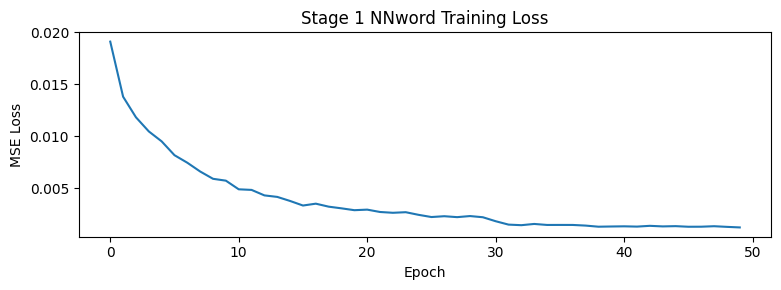

Stage 1 完成


In [12]:
model_word = NNword(BERT_DIM).to(device)
opt_word   = optim.AdamW(model_word.parameters(), lr=1e-3, weight_decay=0.01)
sch_word   = optim.lr_scheduler.StepLR(opt_word, step_size=30, gamma=0.5)
word_ds    = TensorDataset(wt_v, wt_y_v, wt_y_a)
word_dl    = DataLoader(word_ds, batch_size=64, shuffle=True)

print('=== Stage 1：訓練 NNword ===')
N_EPOCHS_WORD = 50; losses_w = []
for epoch in range(N_EPOCHS_WORD):
    model_word.train(); epoch_loss = 0.0
    for bvec, by_v, by_a in word_dl:
        pred_v, pred_a = model_word(bvec)
        loss = 0.5 * ((pred_v - by_v)**2 + (pred_a - by_a)**2).mean()
        opt_word.zero_grad(); loss.backward(); opt_word.step()
        epoch_loss += loss.item()
    sch_word.step()
    losses_w.append(epoch_loss / len(word_dl))
    if (epoch+1) % 10 == 0:
        print(f'Epoch {epoch+1:3d}/{N_EPOCHS_WORD} | Loss: {losses_w[-1]:.6f}')

plt.figure(figsize=(8,3))
plt.plot(losses_w); plt.title('Stage 1 NNword Training Loss')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.tight_layout(); plt.show()
torch.save(model_word.state_dict(), f'{SAVE_DIR}/nnword.pt')
print('Stage 1 完成')


## Stage 2 訓練 NNmod（v7-2 原版）


=== Stage 2：訓練 NNmod（NNword 凍結，遞迴鏈訓練）===
Epoch  20/100 | Loss: 0.003827
Epoch  40/100 | Loss: 0.002599
Epoch  60/100 | Loss: 0.002231
Epoch  80/100 | Loss: 0.001637


Epoch 100/100 | Loss: 0.001351


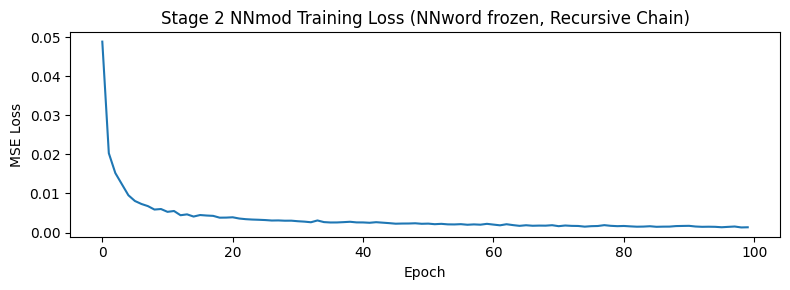

Stage 2 完成


In [13]:
model_mod = NNmod(BERT_DIM).to(device)
for param in model_word.parameters():
    param.requires_grad = False
opt_mod = optim.AdamW(model_mod.parameters(), lr=3e-3, weight_decay=1e-4)

print('=== Stage 2：訓練 NNmod（NNword 凍結，遞迴鏈訓練）===')
N_EPOCHS_MOD = 100; losses_m = []; grad_accum_steps = 16
for epoch in range(N_EPOCHS_MOD):
    model_mod.train(); model_word.eval(); epoch_loss = 0.0
    idxs = np.random.permutation(len(train_chain_samples)); opt_mod.zero_grad()
    for step_i, si in enumerate(idxs, start=1):
        s      = train_chain_samples[si]
        core_t = torch.tensor(s['core_vec']).unsqueeze(0).to(device)
        y_v    = torch.tensor([[s['valence']]], dtype=torch.float32, device=device)
        y_a    = torch.tensor([[s['arousal']]], dtype=torch.float32, device=device)
        with torch.no_grad():
            cur_v, cur_a = model_word(core_t)
        for ctx_np in s['ctx_chain']:
            ctx_t = torch.tensor(ctx_np).unsqueeze(0).to(device)
            cur_v, cur_a, _, _ = model_mod(cur_v, cur_a, ctx_t)
        loss = 0.5 * ((cur_v - y_v)**2 + (cur_a - y_a)**2).mean()
        (loss / grad_accum_steps).backward(); epoch_loss += loss.item()
        if (step_i % grad_accum_steps == 0) or (step_i == len(idxs)):
            torch.nn.utils.clip_grad_norm_(model_mod.parameters(), max_norm=1.0)
            opt_mod.step(); opt_mod.zero_grad()
    losses_m.append(epoch_loss / len(train_chain_samples))
    if (epoch+1) % 20 == 0:
        print(f'Epoch {epoch+1:3d}/{N_EPOCHS_MOD} | Loss: {losses_m[-1]:.6f}')

plt.figure(figsize=(8,3))
plt.plot(losses_m); plt.title('Stage 2 NNmod Training Loss (NNword frozen, Recursive Chain)')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.tight_layout(); plt.show()
torch.save(model_mod.state_dict(), f'{SAVE_DIR}/nnmod.pt')
for param in model_word.parameters():
    param.requires_grad = True
print('Stage 2 完成')


## 建立 CVAS 句子的 Pipeline span 樣本（Stage 3 前置）


In [14]:
print('\n=== Stage 3 前置：建立 CVAS Pipeline span 樣本 ===')
print('策略：滑動窗口直接找「修飾詞+情感詞」短語，最大化 Pipeline 命中率')

MAX_SPANS  = 8
MOD_WINDOW = 6   # 情感詞前最多取幾個字作修飾詞視窗

@torch.no_grad()
def run_full_pipeline(span_text):
    """
    對一個文字片段執行完整 Stage1+2 遞迴鏈。
    回傳：(V, A, c_mod_v, c_mod_a, has_modifier)
      has_modifier=1：找到修飾詞，走完整鏈
      has_modifier=0：只有核心詞，走 NNword
    """
    model_word.eval(); model_mod.eval()
    mod, core, chain = split_phrase(span_text, cvaw_word_set)

    if core is not None and mod:
        # 有修飾詞 → 完整遞迴鏈
        ct = torch.tensor(get_core_vec_cached(core)).unsqueeze(0).to(device)
        cv, ca = model_word(ct)
        cur_label = core
        cmv = torch.tensor([[0.5]], device=device)
        cma = torch.tensor([[0.5]], device=device)
        for m in reversed(chain):
            ctx_t = torch.tensor(get_pair_vec_cached(str(m), cur_label)).unsqueeze(0).to(device)
            cv, ca, cmv, cma = model_mod(cv, ca, ctx_t)
            cur_label = str(m) + cur_label
        return cv.item(), ca.item(), cmv.item(), cma.item(), 1

    elif core is not None:
        # 只有核心詞，無修飾詞 → NNword
        ct = torch.tensor(get_core_vec_cached(core)).unsqueeze(0).to(device)
        cv, ca = model_word(ct)
        return cv.item(), ca.item(), 0.5, 0.5, 0

    else:
        # 找不到情感詞 → NNword 估整段
        vec = torch.tensor(get_bert_vec(span_text)).unsqueeze(0).to(device)
        cv, ca = model_word(vec)
        return cv.item(), ca.item(), 0.5, 0.5, 0


def extract_emotion_spans(sentence, cvaw_words, max_spans=MAX_SPANS, mod_window=MOD_WINDOW):
    """
    滑動窗口：掃描句子，找出所有情感詞，
    往前取修飾詞視窗組成完整短語。
    確保每個 span 都含有情感詞，hit 率大幅提升。
    """
    sentence     = str(sentence).strip()
    found_spans  = []   # [(span_text, mod, core, chain), ...]
    visited_pos  = set()

    i = 0
    while i < len(sentence):
        # 找情感詞（由長到短）
        matched_core = None; matched_len = 0
        for cl in range(min(max_core_len, len(sentence)-i), 0, -1):
            if sentence[i:i+cl] in cvaw_words:
                matched_core = sentence[i:i+cl]
                matched_len  = cl; break

        if matched_core and i not in visited_pos:
            visited_pos.add(i)
            # 往前取修飾詞視窗，嘗試組成完整短語
            best_span = (matched_core, None, matched_core, [])
            for start in range(max(0, i-mod_window), i+1):
                candidate = sentence[start:i+matched_len]
                m, c, ch  = split_phrase(candidate, cvaw_words)
                if c == matched_core and m:
                    best_span = (candidate, m, c, ch); break

            if best_span[0] not in [s[0] for s in found_spans]:
                found_spans.append(best_span)
            i += matched_len
        else:
            i += 1

    # 若沒找到任何情感詞，整句作為 1 個 fallback span
    if not found_spans:
        found_spans = [(sentence, None, None, [])]

    return found_spans[:max_spans]


def build_cvas_pipeline_samples(df, max_spans=MAX_SPANS):
    """
    對 CVAS 每一句建立 Stage 3 的輸入：
      span_vas   (MAX_SPANS, 2)  — Pipeline 最終 VA
      span_cmods (MAX_SPANS, 2)  — NNmod c_mod（修飾詞強度）
      span_hits  (MAX_SPANS, 1)  — 1=有修飾詞完整鏈, 0=其他
      span_mask  (MAX_SPANS,)    — 有效 span mask
    """
    samples = []
    cnt_full = cnt_core = cnt_fb = 0; total = 0

    for _, row in df.iterrows():
        sentence   = str(row['Text'])
        span_items = extract_emotion_spans(sentence, cvaw_word_set, max_spans)

        span_vas   = np.zeros((max_spans, 2), dtype=np.float32)
        span_cmods = np.full((max_spans, 2), 0.5, dtype=np.float32)
        span_hits  = np.zeros((max_spans, 1), dtype=np.float32)
        span_mask  = np.zeros(max_spans,      dtype=np.float32)

        for i, (span_text, mod, core, chain) in enumerate(span_items):
            sv, sa, cmv, cma, hit = run_full_pipeline(span_text)
            span_vas[i]   = [sv, sa]
            span_cmods[i] = [cmv, cma]
            span_hits[i]  = hit
            span_mask[i]  = 1.0
            if mod:   cnt_full += 1
            elif core: cnt_core += 1
            else:      cnt_fb   += 1
            total += 1

        samples.append({
            'span_vas':   span_vas,
            'span_cmods': span_cmods,
            'span_hits':  span_hits,
            'span_mask':  span_mask,
            'valence':    float(row['valence']),
            'arousal':    float(row['arousal']),
            'sentence':   sentence,
        })

    print(f'  完整Pipeline(修飾詞+核心詞): {cnt_full}/{total} ({cnt_full/max(total,1)*100:.1f}%)')
    print(f'  核心詞(無修飾詞):            {cnt_core}/{total} ({cnt_core/max(total,1)*100:.1f}%)')
    print(f'  Fallback(無情感詞):          {cnt_fb}/{total}  ({cnt_fb/max(total,1)*100:.1f}%)')
    return samples


print('計算 CVAS 訓練集 span...')
cvas_train_samples = build_cvas_pipeline_samples(cvas_train)
print('計算 CVAS 測試集 span...')
cvas_test_samples  = build_cvas_pipeline_samples(cvas_test)

# 打包成 TensorDataset
def pack_to_dataset(samples):
    return TensorDataset(
        torch.tensor(np.stack([s['span_vas']   for s in samples])).float(),
        torch.tensor(np.stack([s['span_cmods'] for s in samples])).float(),
        torch.tensor(np.stack([s['span_hits']  for s in samples])).float(),
        torch.tensor(np.stack([s['span_mask']  for s in samples])).float(),
        torch.tensor(np.array([[s['valence'], s['arousal']] for s in samples])).float(),
    )

cvas_train_ds = pack_to_dataset(cvas_train_samples)
cvas_test_ds  = pack_to_dataset(cvas_test_samples)
cvas_train_dl = DataLoader(cvas_train_ds, batch_size=32, shuffle=True)
cvas_test_dl  = DataLoader(cvas_test_ds,  batch_size=32, shuffle=False)

cvas_train_val = np.array([s['valence'] for s in cvas_train_samples], dtype=np.float32)
cvas_train_aro = np.array([s['arousal'] for s in cvas_train_samples], dtype=np.float32)
cvas_test_val  = np.array([s['valence'] for s in cvas_test_samples],  dtype=np.float32)
cvas_test_aro  = np.array([s['arousal'] for s in cvas_test_samples],  dtype=np.float32)
print(f'CVAS 樣本: train={len(cvas_train_samples)}  test={len(cvas_test_samples)}')



=== Stage 3 前置：建立 CVAS Pipeline span 樣本 ===
策略：滑動窗口直接找「修飾詞+情感詞」短語，最大化 Pipeline 命中率
計算 CVAS 訓練集 span...
  完整Pipeline(修飾詞+核心詞): 2546/2827 (90.1%)
  核心詞(無修飾詞):            278/2827 (9.8%)
  Fallback(無情感詞):          3/2827  (0.1%)
計算 CVAS 測試集 span...
  完整Pipeline(修飾詞+核心詞): 632/688 (91.9%)
  核心詞(無修飾詞):            55/688 (8.0%)
  Fallback(無情感詞):          1/688  (0.1%)
CVAS 樣本: train=2066  test=517


## Stage 3 訓練 NNsent


=== Stage 3：訓練 NNsent（NNword + NNmod 凍結）===
Epoch  10/50 | Loss: 0.044902
Epoch  20/50 | Loss: 0.044771
Epoch  30/50 | Loss: 0.044495
Epoch  40/50 | Loss: 0.044328


Epoch  50/50 | Loss: 0.044375


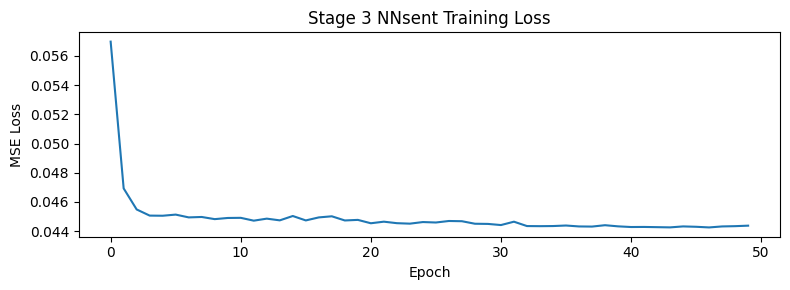

Stage 3 完成


In [15]:
model_sent = NNsent(hidden=64).to(device)
for p in model_word.parameters(): p.requires_grad = False
for p in model_mod.parameters():  p.requires_grad = False

opt_sent   = optim.Adam(model_sent.parameters(), lr=1e-3)
sch_sent   = optim.lr_scheduler.CosineAnnealingLR(opt_sent, T_max=50)
criterion  = nn.MSELoss()

print('=== Stage 3：訓練 NNsent（NNword + NNmod 凍結）===')
N_EPOCHS_SENT = 50; losses_s = []
for epoch in range(N_EPOCHS_SENT):
    model_sent.train(); total_loss = 0.0
    for sv, sc, sh, sm, labels in cvas_train_dl:
        sv = sv.to(device); sc = sc.to(device)
        sh = sh.to(device); sm = sm.to(device)
        yv = labels[:,0:1].to(device)
        ya = labels[:,1:2].to(device)
        pv, pa, _ = model_sent(sv, sc, sh, sm)
        loss = criterion(pv, yv) + criterion(pa, ya)
        opt_sent.zero_grad(); loss.backward(); opt_sent.step()
        total_loss += loss.item()
    sch_sent.step()
    losses_s.append(total_loss / len(cvas_train_dl))
    if (epoch+1) % 10 == 0:
        print(f'Epoch {epoch+1:3d}/{N_EPOCHS_SENT} | Loss: {losses_s[-1]:.6f}')

plt.figure(figsize=(8,3))
plt.plot(losses_s); plt.title('Stage 3 NNsent Training Loss')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.tight_layout(); plt.show()
torch.save(model_sent.state_dict(), f'{SAVE_DIR}/nnsent.pt')
for p in model_word.parameters(): p.requires_grad = True
for p in model_mod.parameters():  p.requires_grad = True
print('Stage 3 完成')


In [16]:
# 診斷 cell：印出 cvas_train_dl 第一個 batch 的內容
import itertools

# 取第一個 batch
sv, sc, sh, sm, labels = next(iter(cvas_train_dl))

print(f"{'='*55}")
print(f"  cvas_train_dl 第一個 batch 內容")
print(f"{'='*55}")
print(f"\n【Shape】")
print(f"  sv     (span_vas)   : {sv.shape}   → (batch, MAX_SPANS, 2)")
print(f"  sc     (span_cmods) : {sc.shape}   → (batch, MAX_SPANS, 2)")
print(f"  sh     (span_hits)  : {sh.shape}  → (batch, MAX_SPANS, 1)")
print(f"  sm     (span_mask)  : {sm.shape}   → (batch, MAX_SPANS)")
print(f"  labels             : {labels.shape}   → (batch, 2)")

print(f"\n【前 5 筆詳細內容】")
for i in range(5):
    n_spans = int(sm[i].sum().item())   # 這句有幾個有效 span
    sent    = cvas_train_samples[i]['sentence']

    print(f"\n  ── 句子 {i} ──────────────────────────────")
    print(f"  原句  : {sent[:40]}")
    print(f"  標籤  : Valence={labels[i,0]:.4f}  Arousal={labels[i,1]:.4f}")
    print(f"  有效 span 數: {n_spans}")
    print(f"  {'span':4s}  {'VA':>16}  {'c_mod':>16}  {'hit':>5}  {'mask':>5}")
    print(f"  {'-'*52}")
    for j in range(n_spans):
        v,  a  = sv[i, j, 0].item(),  sv[i, j, 1].item()
        cv, ca = sc[i, j, 0].item(),  sc[i, j, 1].item()
        hit    = sh[i, j, 0].item()
        mask   = sm[i, j].item()
        print(f"  [{j}]   V={v:.4f} A={a:.4f}  "
              f"cv={cv:.4f} ca={ca:.4f}  "
              f"hit={hit:.0f}  mask={mask:.0f}")

print(f"\n【整體統計】")
valid_mask = sm == 1
print(f"  總有效 span 數 : {valid_mask.sum().item():.0f} / {32*8}")
print(f"  hit=1 的 span  : {sh[valid_mask.unsqueeze(-1).expand_as(sh)].sum().item():.0f}")
print(f"  span VA mean   : V={sv[valid_mask].view(-1,2)[:,0].mean():.4f}  "
      f"A={sv[valid_mask].view(-1,2)[:,1].mean():.4f}")
print(f"  c_mod mean     : cv={sc[valid_mask].view(-1,2)[:,0].mean():.4f}  "
      f"ca={sc[valid_mask].view(-1,2)[:,1].mean():.4f}")
print(f"  c_mod == 0.5 的比例（無修飾詞）: "
      f"{(sc[valid_mask].view(-1,2)[:,0] == 0.5).float().mean()*100:.1f}%")

  cvas_train_dl 第一個 batch 內容

【Shape】
  sv     (span_vas)   : torch.Size([32, 8, 2])   → (batch, MAX_SPANS, 2)
  sc     (span_cmods) : torch.Size([32, 8, 2])   → (batch, MAX_SPANS, 2)
  sh     (span_hits)  : torch.Size([32, 8, 1])  → (batch, MAX_SPANS, 1)
  sm     (span_mask)  : torch.Size([32, 8])   → (batch, MAX_SPANS)
  labels             : torch.Size([32, 2])   → (batch, 2)

【前 5 筆詳細內容】

  ── 句子 0 ──────────────────────────────
  原句  : 卻得到一鼰赤?
  標籤  : Valence=0.3250  Arousal=0.7188
  有效 span 數: 2
  span                VA             c_mod    hit   mask
  ----------------------------------------------------
  [0]   V=0.3523 A=0.6659  cv=0.5385 ca=0.5826  hit=1  mask=1
  [1]   V=0.8872 A=0.7750  cv=0.4583 ca=0.4605  hit=1  mask=1

  ── 句子 1 ──────────────────────────────
  原句  : 清除一大批害群之馬
  標籤  : Valence=0.7500  Arousal=0.3438
  有效 span 數: 1
  span                VA             c_mod    hit   mask
  ----------------------------------------------------
  [0]   V=0.7160 A=0.2869  cv=0.

## 評估函式


In [17]:
def compute_metrics(preds, golds, label):
    p, g   = np.array(preds), np.array(golds)
    mae    = np.mean(np.abs(p - g))
    mse    = np.mean((p - g)**2)
    r, _   = pearsonr(p, g)
    tau, _ = kendalltau(p, g)
    rho, _ = spearmanr(p, g)
    print(f'  {label:30s} | MAE={mae:.4f}  r={r:.4f}  τ={tau:.4f}  ρ={rho:.4f}')
    return mae, mse, r, tau, rho

@torch.no_grad()
def batch_predict_word(vecs_np):
    model_word.eval()
    pv, pa = model_word(torch.tensor(vecs_np).to(device))
    return pv.cpu().numpy().flatten(), pa.cpu().numpy().flatten()

@torch.no_grad()
def batch_predict_phrase_recursive(samples):
    model_word.eval(); model_mod.eval()
    all_pv, all_pa = [], []
    for s in samples:
        ct = torch.tensor(s['core_vec']).unsqueeze(0).to(device)
        cv, ca = model_word(ct)
        for ctx_np in s['ctx_chain']:
            cv, ca, _, _ = model_mod(cv, ca, torch.tensor(ctx_np).unsqueeze(0).to(device))
        all_pv.append(cv.item()); all_pa.append(ca.item())
    return np.array(all_pv), np.array(all_pa)

@torch.no_grad()
def batch_predict_sent(dl):
    model_sent.eval(); all_pv, all_pa = [], []
    for sv, sc, sh, sm, _ in dl:
        pv, pa, _ = model_sent(sv.to(device), sc.to(device), sh.to(device), sm.to(device))
        all_pv.append(pv.cpu().numpy()); all_pa.append(pa.cpu().numpy())
    return np.concatenate(all_pv).flatten(), np.concatenate(all_pa).flatten()


## 完整評估對照表


In [18]:
print('='*75)
print('完整三階段評估對照表（0–1 尺度）')
print('='*75)

pv_wtr, pa_wtr = batch_predict_word(word_train_vecs)
pv_wte, pa_wte = batch_predict_word(word_test_vecs)
pv_ptr, pa_ptr = batch_predict_phrase_recursive(train_chain_samples)
pv_pte, pa_pte = batch_predict_phrase_recursive(test_chain_samples)
pv_str, pa_str = batch_predict_sent(cvas_train_dl)
pv_ste, pa_ste = batch_predict_sent(cvas_test_dl)

for stage, split, pv, pa, gv, ga in [
    ('S1 NNword  (CVAW)', '訓練', pv_wtr, pa_wtr, word_train_val,  word_train_aro),
    ('S1 NNword  (CVAW)', '測試', pv_wte, pa_wte, word_test_val,   word_test_aro),
    ('S2 Pipeline(CVAP)', '訓練', pv_ptr, pa_ptr, phrase_train_val,phrase_train_aro),
    ('S2 Pipeline(CVAP)', '測試', pv_pte, pa_pte, phrase_test_val, phrase_test_aro),
    ('S3 NNsent  (CVAS)', '訓練', pv_str, pa_str, cvas_train_val,  cvas_train_aro),
    ('S3 NNsent  (CVAS)', '測試', pv_ste, pa_ste, cvas_test_val,   cvas_test_aro),
]:
    print(f'\n[{stage}] {split}')
    compute_metrics(pv, gv, 'Valence')
    compute_metrics(pa, ga, 'Arousal')


完整三階段評估對照表（0–1 尺度）

[S1 NNword  (CVAW)] 訓練
  Valence                        | MAE=0.0159  r=0.9956  τ=0.9458  ρ=0.9943
  Arousal                        | MAE=0.0206  r=0.9925  τ=0.9358  ρ=0.9924

[S1 NNword  (CVAW)] 測試
  Valence                        | MAE=0.0746  r=0.8729  τ=0.6596  ρ=0.8443
  Arousal                        | MAE=0.1112  r=0.6215  τ=0.4346  ρ=0.6028

[S2 Pipeline(CVAP)] 訓練
  Valence                        | MAE=0.0252  r=0.9878  τ=0.9075  ρ=0.9842
  Arousal                        | MAE=0.0204  r=0.9852  τ=0.8943  ρ=0.9840

[S2 Pipeline(CVAP)] 測試
  Valence                        | MAE=0.0513  r=0.9494  τ=0.8056  ρ=0.9450
  Arousal                        | MAE=0.0511  r=0.9024  τ=0.7160  ρ=0.8914

[S3 NNsent  (CVAS)] 訓練
  Valence                        | MAE=0.1649  r=-0.0093  τ=-0.0089  ρ=-0.0129
  Arousal                        | MAE=0.1356  r=0.0090  τ=0.0008  ρ=0.0006

[S3 NNsent  (CVAS)] 測試
  Valence                        | MAE=0.1158  r=0.5989  τ=0.4177  ρ=0.582

## 散點圖


/tmp/ipykernel_1751/360022511.py:19: UserWarning: Glyph 19977 (\N{CJK UNIFIED IDEOGRAPH-4E09}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1751/360022511.py:19: UserWarning: Glyph 38542 (\N{CJK UNIFIED IDEOGRAPH-968E}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1751/360022511.py:19: UserWarning: Glyph 27573 (\N{CJK UNIFIED IDEOGRAPH-6BB5}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1751/360022511.py:19: UserWarning: Glyph 38928 (\N{CJK UNIFIED IDEOGRAPH-9810}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1751/360022511.py:19: UserWarning: Glyph 28204 (\N{CJK UNIFIED IDEOGRAPH-6E2C}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1751/360022511.py:19: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1751/36002251

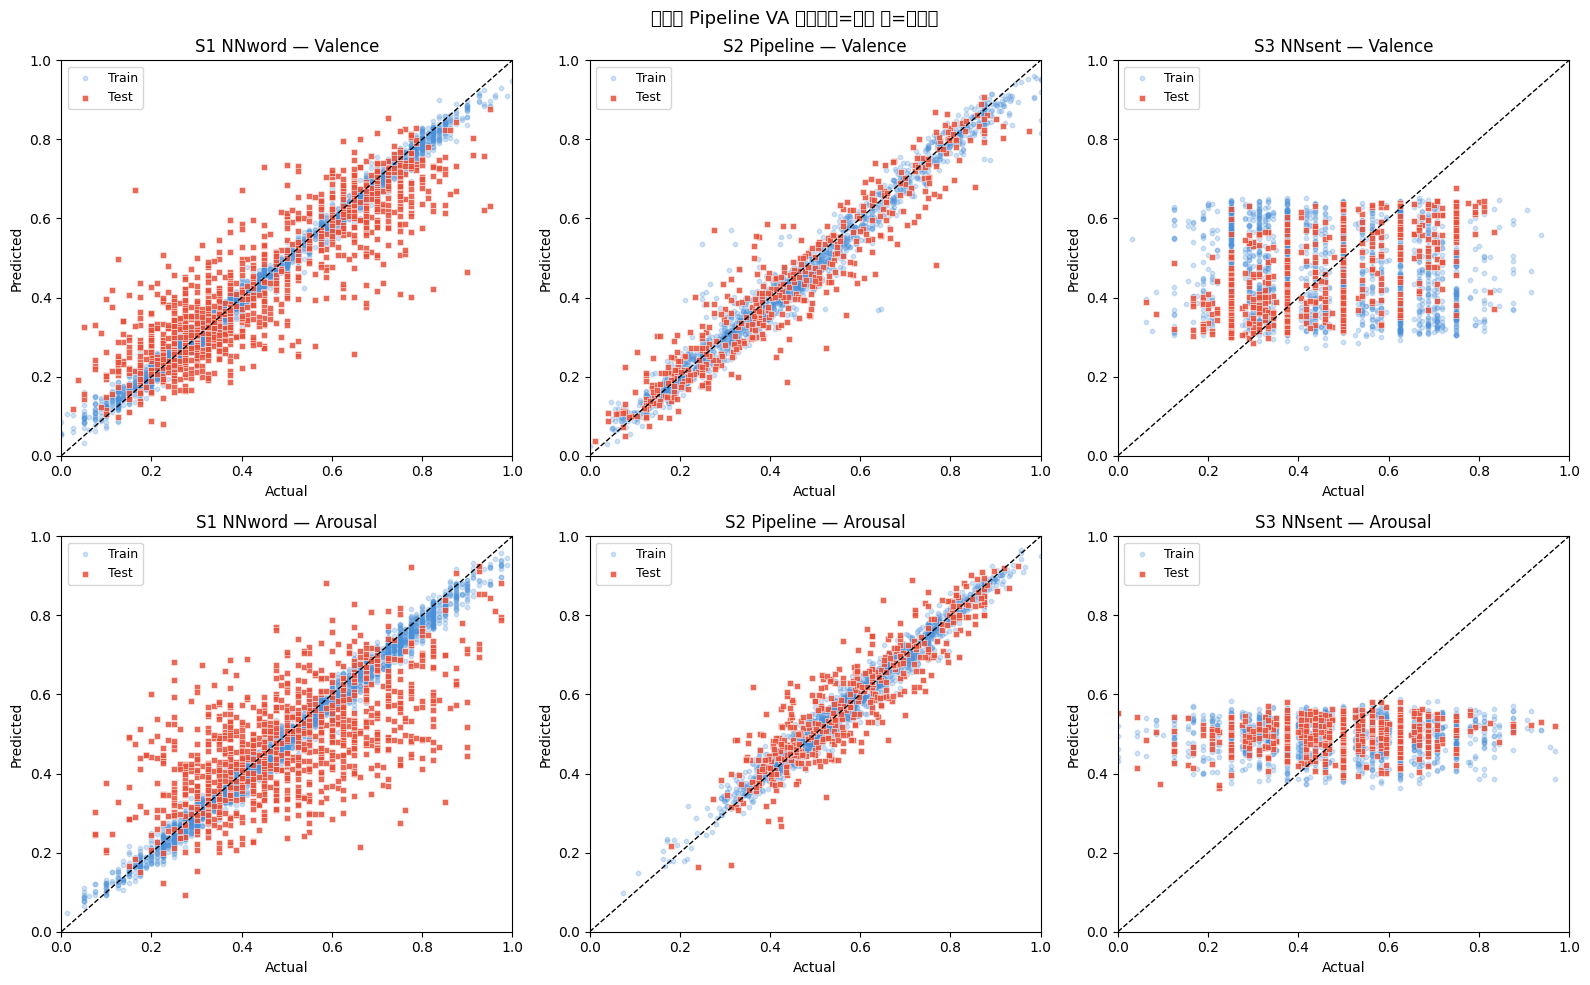

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('三階段 Pipeline VA 預測（藍=訓練 紅=測試）', fontsize=13)
configs = [
    (axes[0,0], pv_wtr, word_train_val,   pv_wte, word_test_val,   'S1 NNword — Valence'),
    (axes[0,1], pv_ptr, phrase_train_val, pv_pte, phrase_test_val, 'S2 Pipeline — Valence'),
    (axes[0,2], pv_str, cvas_train_val,   pv_ste, cvas_test_val,   'S3 NNsent — Valence'),
    (axes[1,0], pa_wtr, word_train_aro,   pa_wte, word_test_aro,   'S1 NNword — Arousal'),
    (axes[1,1], pa_ptr, phrase_train_aro, pa_pte, phrase_test_aro, 'S2 Pipeline — Arousal'),
    (axes[1,2], pa_str, cvas_train_aro,   pa_ste, cvas_test_aro,   'S3 NNsent — Arousal'),
]
for ax, ptr, gtr, pte, gte, title in configs:
    ax.scatter(gtr, ptr, alpha=0.25, s=10, color='#4A90D9', label='Train')
    ax.scatter(gte, pte, alpha=0.85, s=20, color='#E8503A',
               marker='s', edgecolors='white', lw=0.4, label='Test')
    ax.plot([0,1],[0,1],'k--', lw=1)
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_xlabel('Actual'); ax.set_ylabel('Predicted')
    ax.set_title(title); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()


## 句子推論 Demo


In [20]:
@torch.no_grad()
def predict_sentence(sentence, verbose=True):
    model_word.eval(); model_mod.eval(); model_sent.eval()
    span_items = extract_emotion_spans(sentence, cvaw_word_set)

    span_vas   = np.zeros((MAX_SPANS, 2), dtype=np.float32)
    span_cmods = np.full((MAX_SPANS, 2), 0.5, dtype=np.float32)
    span_hits  = np.zeros((MAX_SPANS, 1), dtype=np.float32)
    span_mask  = np.zeros(MAX_SPANS,      dtype=np.float32)
    span_infos = []

    if verbose:
        print(f'\n句子：「{sentence}」')
        print(f'找到 {len(span_items)} 個情感 span：')

    for i, (span_text, mod, core, chain) in enumerate(span_items):
        sv, sa, cmv, cma, hit = run_full_pipeline(span_text)
        span_vas[i]   = [sv, sa]
        span_cmods[i] = [cmv, cma]
        span_hits[i]  = hit
        span_mask[i]  = 1.0
        kind = '完整Pipeline' if (mod and hit) else ('核心詞' if core else 'Fallback')
        span_infos.append((span_text, kind, sv, sa, cmv, cma))
        if verbose:
            print(f'  [{kind}] 「{span_text}」→ V={sv:.4f} A={sa:.4f}  cmod_v={cmv:.4f} cmod_a={cma:.4f}')

    sv_t = torch.tensor(span_vas).unsqueeze(0).to(device)
    sc_t = torch.tensor(span_cmods).unsqueeze(0).to(device)
    sh_t = torch.tensor(span_hits).unsqueeze(0).to(device)
    sm_t = torch.tensor(span_mask).unsqueeze(0).to(device)
    pv, pa, attn_w = model_sent(sv_t, sc_t, sh_t, sm_t)

    fv9 = round(pv.item()*8+1, 3)
    fa9 = round(pa.item()*8+1, 3)
    pol = '正向' if pv.item()>0.625 else ('負向' if pv.item()<0.375 else '中性')
    act = '高喚起' if pa.item()>0.625 else ('低喚起' if pa.item()<0.375 else '中喚起')

    if verbose:
        attn_np = attn_w[0].cpu().numpy()
        print(f'\n注意力權重（NNsent 認為哪個 span 最重要）：')
        for (sp, kind, sv, sa, cmv, cma), w in zip(span_infos, attn_np[:len(span_infos)]):
            bar = '█' * int(w * 30)
            print(f'  {w:.4f}  {bar}  「{sp}」')
        print(f'\n整句 VA（1–9）→ Valence={fv9}  Arousal={fa9}  [{pol}/{act}]')
    return fv9, fa9

print('\n=== 句子推論 Demo ===')
for s in [
    '這次旅行真的非常開心，風景美極了！',
    '主治醫師強調血液透析，家屬却遲遲無法達到共識。',
    '視病如親，讓我十分的動容。',
    '雖然考試沒過，但心情還算平靜。',
    '非常憤怒，完全無法接受這種行為！',
]:
    predict_sentence(s)


=== 句子推論 Demo ===

句子：「這次旅行真的非常開心，風景美極了！」
找到 1 個情感 span：
  [完整Pipeline] 「旅行真的非常開心」→ V=0.4690 A=0.6244  cmod_v=0.3812 cmod_a=0.4670

注意力權重（NNsent 認為哪個 span 最重要）：
  1.0000  ██████████████████████████████  「旅行真的非常開心」

整句 VA（1–9）→ Valence=5.127  Arousal=4.949  [中性/中喚起]

句子：「主治醫師強調血液透析，家屬却遲遲無法達到共識。」
找到 3 個情感 span：
  [完整Pipeline] 「主治醫師強」→ V=0.4947 A=0.6817  cmod_v=0.4129 cmod_a=0.4483
  [完整Pipeline] 「，家屬却遲遲無法」→ V=0.2474 A=0.7653  cmod_v=0.4728 cmod_a=0.6062
  [完整Pipeline] 「屬却遲遲無法達到」→ V=0.5242 A=0.7914  cmod_v=0.4974 cmod_a=0.5581

注意力權重（NNsent 認為哪個 span 最重要）：
  0.1346  ████  「主治醫師強」
  0.6546  ███████████████████  「，家屬却遲遲無法」
  0.2108  ██████  「屬却遲遲無法達到」

整句 VA（1–9）→ Valence=4.551  Arousal=5.306  [中性/中喚起]

句子：「視病如親，讓我十分的動容。」
找到 1 個情感 span：
  [完整Pipeline] 「視病如親」→ V=0.6727 A=0.7502  cmod_v=0.5090 cmod_a=0.5828

注意力權重（NNsent 認為哪個 span 最重要）：
  1.0000  ██████████████████████████████  「視病如親」

整句 VA（1–9）→ Valence=5.851  Arousal=5.093  [中性/中喚起]

句子：「雖然考試沒過，但心情還算平靜。」
找到 2 個情感 span：
  [完整Pipeline] 「考試沒